In [1]:
pip install --upgrade keras

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 17.8 MB/s  0:00:00
  Attempting uninstall: keras
    Found existing installation: keras 3.13.2
    Uninstalling keras-3.13.2:
      Successfully uninstalled keras-3.13.2
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
os.environ['KERAS_BACKEND'] = 'torch'

import cv2
import numpy as np
import matplotlib.pyplot as plt

import keras
from keras import layers, regularizers
from keras.layers import (
    Concatenate,
    Conv2D,
    Conv2DTranspose,
    Input,
    MaxPooling2D,
    LeakyReLU
)
from keras.models import Model
from keras import ops

import torch
import math
import glob
import random

# Reproducibility
seed_value = 1234578790

np.random.seed(seed_value)
torch.manual_seed(seed_value)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed_value)
print("keras.__version__", keras.__version__)

keras.__version__ 3.15.1


In [38]:
def preprocess(array):
    array = array.astype("float32") / 255.0
    array = cv2.resize(array, (192, 72))
    return array

def noise(array):
    noise_factor = 0.4
    noisy_array = array + noise_factor * np.random.normal(loc=0.0, scale=1.0, size=array.shape)
    return np.clip(noisy_array, 0.0, 1.0)

def noise_blur(array):
    noise_factor = random.randint(5, 15)
    array = cv2.blur(array,(noise_factor,noise_factor))
    return np.clip(array, 0.0, 1.0)

degtorad = 0.01745329252
radtodeg = 1/degtorad;

# returns a list of lines
def rand_lines(w,h,a,l,nrs):
    lines=[]
    for i in range(nrs):
        # randomize starting and ending points for 2D lines
        sx = random.randint(0,w-1)
        sy = random.randint(0,h-1)

        le = random.randint(1,l)
        ang = a + random.randint(0,10)
        ex = sx + int(le * math.sin(ang * degtorad))
        ey = sy + int(le * math.cos(ang * degtorad))
        # move the endpoints inside the image frame
        if ex<0: ex = 0
        if ex>w-1: ex=w-1
        if ey<0: ey = 0
        if ey>w-1: ey=h-1
        # add line to list
        lines.append({'sx':sx,'sy':sy,'ex':ex,'ey':ey})
    return lines

def add_rain(img):
    angle = random.randint(30, 150)
    drop_length = random.randint(4, 15)
    drop_thickness = random.randint(1, 3)
    drop_nrs = random.randint(100, 150)
    blur = random.randint(1, 5)
    intensity = random.randint(75, 140)
    # create placehplder for rain
    rain=np.zeros((img.shape[0],img.shape[1],img.shape[2]),dtype='uint16')
    # generate random lines
    lines=rand_lines(rain.shape[1],rain.shape[0],angle,drop_length,drop_nrs)
    # draw lines to the image
    for l in lines:
        cv2.line(rain,(l['sx'],l['sy']),(l['ex'],l['ey']),(intensity,intensity,intensity),drop_thickness)
    # add blur to the lines
    rain = cv2.blur(rain,(blur,blur))
    rain = rain / 255.0
    #cv2.addWeighted(img, 0.7, rain, 0.3, 0)
    return np.clip(img + rain, 0.0, 1.0)
    
def display(data_generator, batch_size):
    for array1, array2 in data_generator:
        n = min(4, len(array1))
        indices = np.random.choice(len(array1), size=n, replace=False)

        images1 = array1[indices]
        images2 = array2[indices]

        plt.figure(figsize=(16, 6))

        for i, (image1, image2) in enumerate(zip(images1, images2)):
            ax = plt.subplot(2, n, i + 1)
            plt.imshow(image1)
            ax.axis('off')

            ax = plt.subplot(2, n, i + 1 + n)
            plt.imshow(image2)
            ax.axis('off')

        plt.tight_layout()
        plt.show()

        break

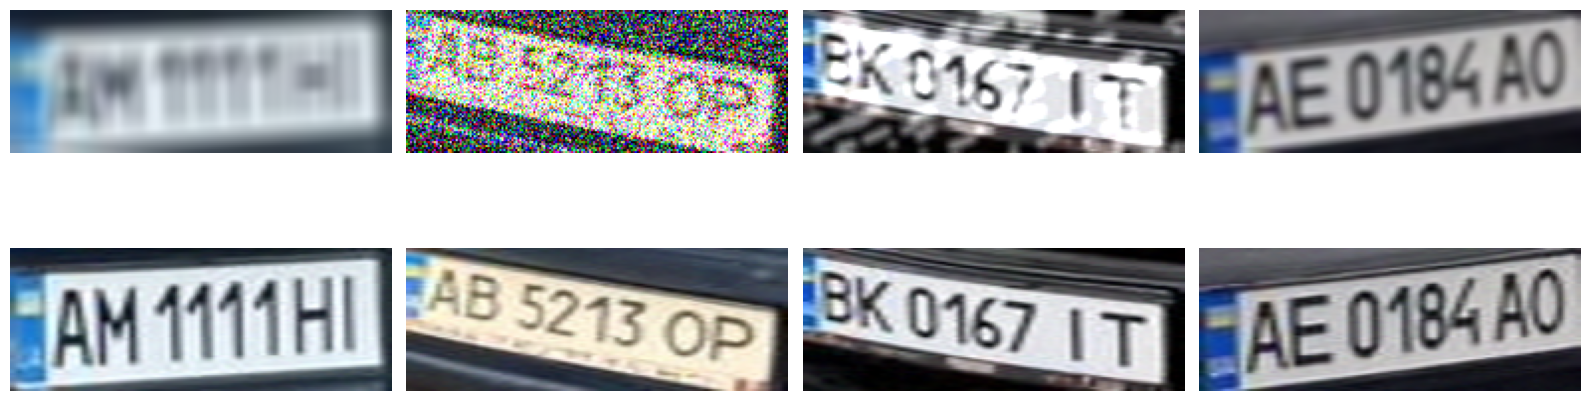

In [39]:
#https://zenodo.org/records/13342103
#Synthetic Ukrainian license plate dataset for the paper "License plate images generation with diffusion models" (presented at PAIS 2024)
def load_data(images_path, batch_size, training=True):
    img_files = glob.glob(os.path.join(images_path, '*.png'))
    noise_functions = [noise_blur, noise, add_rain]
    while True:
      if training:
        random.shuffle(img_files)
      #print(len(img_files))
      for i in range(0, len(img_files), batch_size):
        batch_files = img_files[i:i + batch_size]
        images = []
        noisy_images = []

        for img_path in batch_files:
            image = cv2.imread(img_path)
            if image is None:
                raise ValueError(f"Cannot read image: {img_path}")
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
            image = preprocess(image)
            noisy_image = random.choice(noise_functions)(image)
            images.append(image)
            noisy_images.append(noisy_image)
        yield (np.asarray(noisy_images, dtype=np.float32), np.asarray(images, dtype=np.float32))

TRAIN_IMG_PATH = '/kaggle/input/datasets/igorpilipets/synthetic-ukrainian-lp-dataset/train/images'
VALIDATION_IMG_PATH = '/kaggle/input/datasets/igorpilipets/synthetic-ukrainian-lp-dataset/valid/images'
BATCH_SIZE = 16

train_generator = load_data(TRAIN_IMG_PATH, BATCH_SIZE, training=True)
validation_generator = load_data(VALIDATION_IMG_PATH, BATCH_SIZE, training=False)

display(train_generator, BATCH_SIZE)

In [40]:
train_batch = next(train_generator)
validation_batch = next(validation_generator)

print("Training:")
print("Input:", train_batch[0].shape)
print("Target:", train_batch[1].shape)

print("\nValidation:")
print("Input:", validation_batch[0].shape)
print("Target:", validation_batch[1].shape)

Training:
Input: (16, 72, 192, 3)
Target: (16, 72, 192, 3)

Validation:
Input: (16, 72, 192, 3)
Target: (16, 72, 192, 3)


In [41]:
inputs = layers.Input(shape=(72, 192, 3))
# Encoder
c1 = Conv2D(32, 3, padding='same')(inputs)
c1 = LeakyReLU(negative_slope=0.01)(c1)
c1 = Conv2D(32, 3, padding='same')(c1)
c1 = LeakyReLU(negative_slope=0.01)(c1)
p1 = MaxPooling2D(2)(c1)

c2 = Conv2D(64, 3, padding='same')(p1)
c2 = LeakyReLU(negative_slope=0.01)(c2)
c2 = Conv2D(64, 3, padding='same')(c2)
c2 = LeakyReLU(negative_slope=0.01)(c2)
p2 = MaxPooling2D(2)(c2)

c3 = Conv2D(128, 3, padding='same')(p2)
c3 = LeakyReLU(negative_slope=0.01)(c3)
c3 = Conv2D(128, 3, padding='same')(c3)
c3 = LeakyReLU(negative_slope=0.01)(c3)
p3 = MaxPooling2D(2)(c3)


# Bottleneck
b = Conv2D(256, 3, activation='relu', padding='same')(p3)
b = Conv2D(256, 3, activation='relu', padding='same')(b)

# Decoder
u3 = Conv2DTranspose(128, 2, strides=2, padding='same')(b)
u3 = Concatenate()([u3, c3])
c4 = Conv2D(128, 3, padding='same')(u3)
c4 = LeakyReLU(negative_slope=0.01)(c4)
c4 = Conv2D(128, 3, padding='same')(c4)
c4 = LeakyReLU(negative_slope=0.01)(c4)

u2 = Conv2DTranspose(64, 2, strides=2, padding='same')(c4)
u2 = Concatenate()([u2, c2])
c5 = Conv2D(64, 3, padding='same')(u2)
c5 = LeakyReLU(negative_slope=0.01)(c5)
c5 = Conv2D(64, 3, padding='same')(c5)
c5 = LeakyReLU(negative_slope=0.01)(c5)

u1 = Conv2DTranspose(32, 2, strides=2, padding='same')(c5)
u1 = Concatenate()([u1, c1])
c6 = Conv2D(32, 3, padding='same')(u1)
c6 = LeakyReLU(negative_slope=0.01)(c6)
c6 = Conv2D(32, 3, padding='same')(c6)
c6 = LeakyReLU(negative_slope=0.01)(c6)

outputs = layers.Conv2D(3, (3, 3), activation="sigmoid", padding="same")(c6)

autoencoder = Model(inputs, outputs)
#Accuracy is not a useful metric for continuous-valued image reconstruction. For example, predicting a pixel value
#of 0.51 instead of 0.50 is a small error,
def combined_loss(y_true, y_pred):
    ssim_value = ops.mean(1.0 - ops.image.ssim(y_true, y_pred, max_val=1.0, filter_size=11, filter_sigma=1.5))
    mse_value = keras.ops.mean(keras.ops.abs(y_true - y_pred))
    return 0.75 * ssim_value + 0.25 * mse_value
    
autoencoder.compile(optimizer='adam', loss=combined_loss, metrics=[keras.metrics.MeanAbsoluteError(name="mae")])
autoencoder.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 72, 192,   │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_15 (Conv2D)  │ (None, 72, 192,   │        896 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_12      │ (None, 72, 192,   │          0 │ conv2d_15[0][0]   │
│ (LeakyReLU)         │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_16 (Conv2D)  │ (None, 72, 192,   │      9,248 │ leaky_re_lu_12[0… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_13      │ (None, 72, 192,   │          0 │ conv2d_16[0][0]   │
│ (LeakyReLU)         │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 36, 96,    │          0 │ leaky_re_lu_13[0… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_17 (Conv2D)  │ (None, 36, 96,    │     18,496 │ max_pooling2d_3[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_14      │ (None, 36, 96,    │          0 │ conv2d_17[0][0]   │
│ (LeakyReLU)         │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_18 (Conv2D)  │ (None, 36, 96,    │     36,928 │ leaky_re_lu_14[0… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_15      │ (None, 36, 96,    │          0 │ conv2d_18[0][0]   │
│ (LeakyReLU)         │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_4     │ (None, 18, 48,    │          0 │ leaky_re_lu_15[0… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_19 (Conv2D)  │ (None, 18, 48,    │     73,856 │ max_pooling2d_4[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_16      │ (None, 18, 48,    │          0 │ conv2d_19[0][0]   │
│ (LeakyReLU)         │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_20 (Conv2D)  │ (None, 18, 48,    │    147,584 │ leaky_re_lu_16[0… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_17      │ (None, 18, 48,    │          0 │ conv2d_20[0][0]   │
│ (LeakyReLU)         │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_5     │ (None, 9, 24,     │          0 │ leaky_re_lu_17[0… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_21 (Conv2D)  │ (None, 9, 24,     │    295,168 │ max_pooling2d_5[

 Total params: 1,926,435 (7.35 MB)

 Trainable params: 1,926,435 (7.35 MB)

 Non-trainable params: 0 (0.00 B)

In [42]:
train_size = len(glob.glob(os.path.join(TRAIN_IMG_PATH, '*.png')))

validation_size = len(glob.glob(os.path.join(VALIDATION_IMG_PATH, '*.png')))

EPOCHS = 25
STEPS_PER_EPOCH = math.ceil(train_size / BATCH_SIZE)
VALIDATION_STEPS = math.ceil(validation_size / BATCH_SIZE)
print("STEPS_PER_EPOCH: ", STEPS_PER_EPOCH)
print("VALIDATION_STEPS: ", VALIDATION_STEPS)

checkpoint = keras.callbacks.ModelCheckpoint('best_model.keras', monitor='val_loss', save_best_only=True, verbose=1)
earlyStop = keras.callbacks.EarlyStopping(monitor='val_loss', mode='min', patience = 7, restore_best_weights=True, verbose=1)

history = autoencoder.fit(train_generator, steps_per_epoch=STEPS_PER_EPOCH, epochs=EPOCHS,
                          validation_data=validation_generator, validation_steps=VALIDATION_STEPS,
                          callbacks=[checkpoint, earlyStop], verbose=2)

STEPS_PER_EPOCH:  500
VALIDATION_STEPS:  63
Epoch 1/25

Epoch 1: val_loss improved from None to 0.14737, saving model to best_model.keras

Epoch 1: finished saving model to best_model.keras
500/500 - 104s - 208ms/step - loss: 0.2225 - mae: 0.0820 - val_loss: 0.1474 - val_mae: 0.0569
Epoch 2/25

Epoch 2: val_loss improved from 0.14737 to 0.10808, saving model to best_model.keras

Epoch 2: finished saving model to best_model.keras
500/500 - 104s - 207ms/step - loss: 0.1247 - mae: 0.0519 - val_loss: 0.1081 - val_mae: 0.0471
Epoch 3/25

Epoch 3: val_loss improved from 0.10808 to 0.09502, saving model to best_model.keras

Epoch 3: finished saving model to best_model.keras
500/500 - 103s - 207ms/step - loss: 0.1001 - mae: 0.0438 - val_loss: 0.0950 - val_mae: 0.0450
Epoch 4/25

Epoch 4: val_loss improved from 0.09502 to 0.08152, saving model to best_model.keras

Epoch 4: finished saving model to best_model.keras
500/500 - 104s - 207ms/step - loss: 0.0883 - mae: 0.0404 - val_loss: 0.0815 - val

Train mae      0.026856865733861923
Validation mae 0.026109864935278893


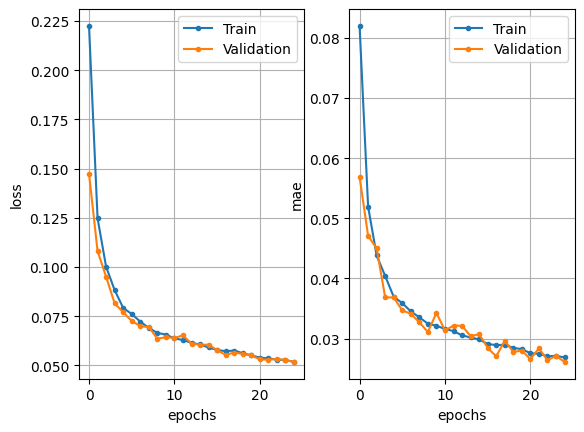

In [43]:
def plot_history(history):
    h = history.history
    epochs = range(len(h['loss']))

    plt.subplot(121), plt.plot(epochs, h['loss'], '.-', epochs, h['val_loss'], '.-')
    plt.grid(True), plt.xlabel('epochs'), plt.ylabel('loss')
    plt.legend(['Train', 'Validation'])
    plt.subplot(122), plt.plot(epochs, h['mae'], '.-',
                               epochs, h['val_mae'], '.-')
    plt.grid(True), plt.xlabel('epochs'), plt.ylabel('mae')
    plt.legend(['Train', 'Validation'])

    print('Train mae     ', h['mae'][-1])
    print('Validation mae', h['val_mae'][-1])

plot_history(history)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
Noisy images: (16, 72, 192, 3)
Predictions: (16, 72, 192, 3)
Clean images: (16, 72, 192, 3)


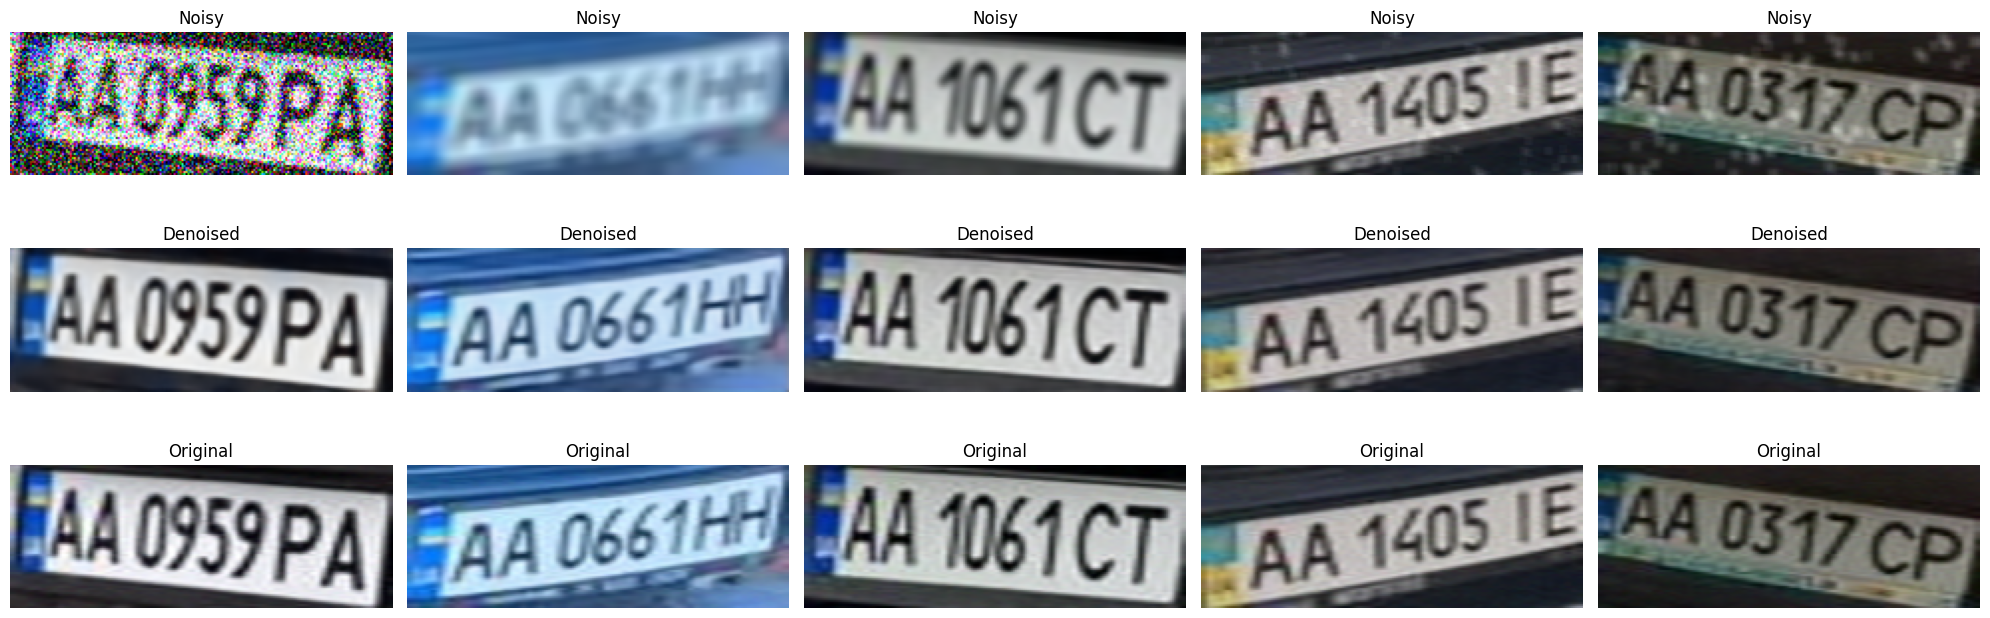

In [49]:
def display_predictions(noisy_images, predictions, clean_images, n=10):
    n = min(n, len(noisy_images))

    indices = np.random.choice(len(noisy_images), size=n, replace=False)
    images1 = noisy_images[indices]
    images2 = predictions[indices]
    images3 = clean_images[indices]
    plt.figure(figsize=(20, 7))
    for i in range(n):
        # Noisy input
        ax = plt.subplot(3, n, i + 1)
        ax.imshow(np.clip(images1[i], 0, 1))
        ax.set_title("Noisy")
        ax.axis("off")
        # Denoised prediction
        ax = plt.subplot(3, n, i + 1 + n)
        ax.imshow(np.clip(images2[i], 0, 1))
        ax.set_title("Denoised")
        ax.axis("off")
        # Original clean image
        ax = plt.subplot(3, n, i + 1 + 2*n)
        ax.imshow(np.clip(images3[i], 0, 1))
        ax.set_title("Original")
        ax.axis("off")

    plt.tight_layout()
    plt.show()

TEST_IMG_PATH = '/kaggle/input/datasets/igorpilipets/synthetic-ukrainian-lp-dataset/test/images'
test_generator = load_data(TEST_IMG_PATH, BATCH_SIZE, training=False)
test_batch = next(test_generator)
noisy_images = test_batch[0]
clean_images = test_batch[1]

best_model = keras.models.load_model('/kaggle/working/best_model.keras', custom_objects={'combined_loss': combined_loss})
predictions = best_model.predict(noisy_images)

print("Noisy images:", noisy_images.shape)
print("Predictions:", predictions.shape)
print("Clean images:", clean_images.shape)

display_predictions(noisy_images, predictions, clean_images, n=5)

Images in directory:  29
Noisy images: (350, 525, 3)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step


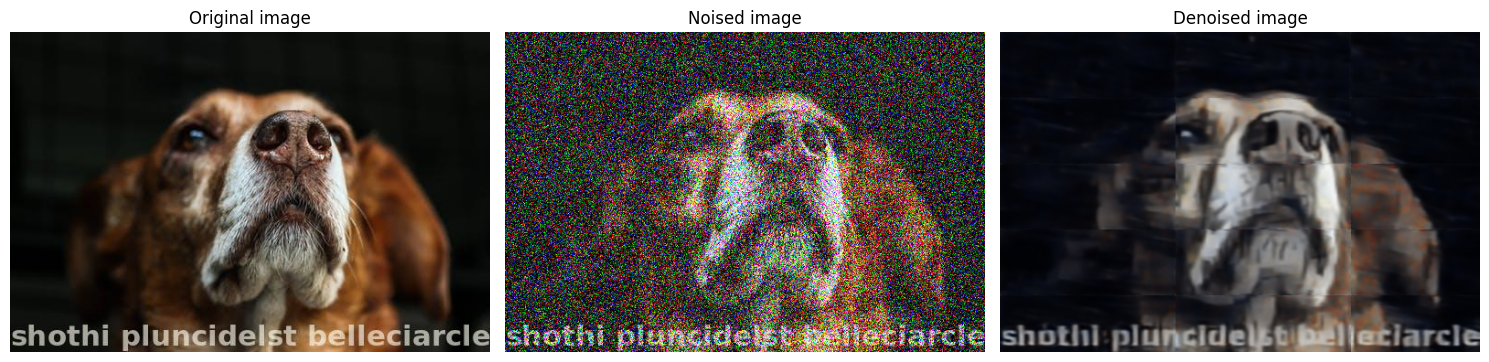

In [50]:
#lets test model on other (bigger) images with watermaks

OTHER_DIR = '/kaggle/input/datasets/felicepollano/watermarked-not-watermarked-images/wm-nowm/valid/watermark'

def load_other_data(images_path):
    img_files = glob.glob(os.path.join(images_path, '*.jpg'))
    print("Images in directory: ", len(img_files))
    images = []
    for image_path in img_files:
        image = cv2.imread(image_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = image.astype("float32") / 255.0
        images.append(image)
    return images

def divide_image(img, noise_function):
    image_parts = []
    h, w, _ = img.shape
    patch_h = 72
    patch_w = 192
    # Number of patches (rounding up)
    n_rows = (h + patch_h - 1) // patch_h
    n_cols = (w + patch_w - 1) // patch_w
    for i in range(n_rows):
        for j in range(n_cols):
            y1 = i * patch_h
            x1 = j * patch_w
            y2 = min(y1 + patch_h, h)
            x2 = min(x1 + patch_w, w)
            img_part = img[y1:y2, x1:x2, :]
            # Pad incomplete patches
            pad_h = patch_h - img_part.shape[0]
            pad_w = patch_w - img_part.shape[1]
            img_part = cv2.copyMakeBorder(img_part, 0, pad_h, 0, pad_w, cv2.BORDER_REFLECT)
            img_part = noise_function(img_part)
            #np.clip(img_part, 0.0, 1.0)
            image_parts.append(img_part)
    return image_parts

def imgReconstruct(image_parts, original_shape):
    h, w, c = original_shape
    patch_h = 72
    patch_w = 192
    n_rows = (h + patch_h - 1) // patch_h
    n_cols = (w + patch_w - 1) // patch_w

    reconstructed = np.zeros((h, w, c), dtype=np.float32)
    idx = 0
    for i in range(n_rows):
        for j in range(n_cols):
            y1 = i * patch_h
            x1 = j * patch_w
            y2 = min(y1 + patch_h, h)
            x2 = min(x1 + patch_w, w)
            # Remove padding by cropping to original dimensions
            patch = image_parts[idx]
            patch = patch[:y2-y1, :x2-x1, :]
            reconstructed[y1:y2, x1:x2, :] = patch
            idx += 1
    return reconstructed

test_img_set = load_other_data(OTHER_DIR)
original_image = test_img_set[10]
print("Noisy images:", original_image.shape)

original_shape = original_image.shape
div_image = divide_image(original_image, noise)
# Convert list of patches into NumPy array
div_image = np.array(div_image, dtype=np.float32)
#print("Inputs shape:", div_image.shape)
original_noised_image = imgReconstruct(div_image, original_shape)

predictions = best_model.predict(div_image)
#print("Predictions shape:", predictions.shape)

result = imgReconstruct(predictions, original_shape)

plt.figure(figsize=(15, 6))

plt.subplot(131), plt.imshow(original_image)
plt.title("Original image")
plt.axis('off')

plt.subplot(132), plt.imshow(original_noised_image)
plt.title("Noised image")
plt.axis('off')

plt.subplot(133), plt.imshow(result)
plt.title("Denoised image")
plt.axis('off')

plt.tight_layout()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step


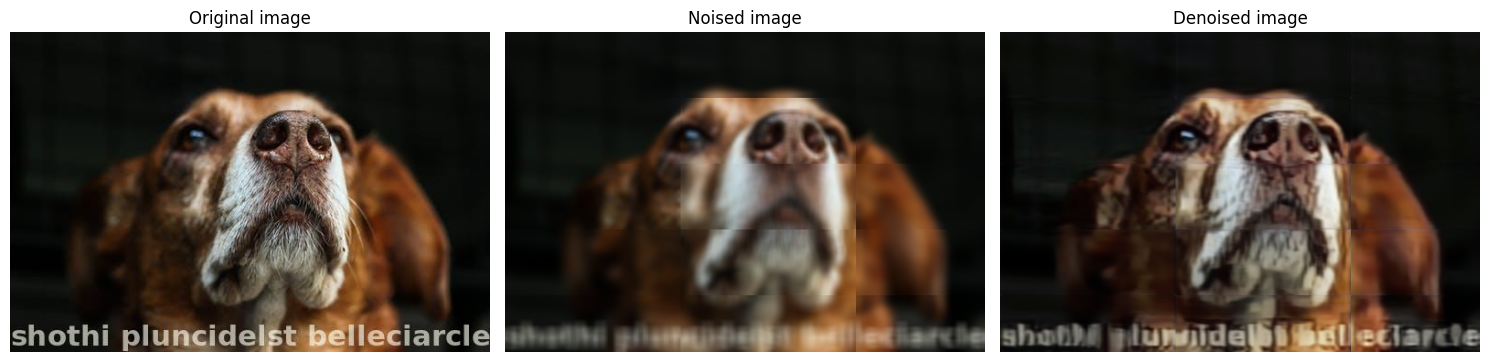

In [51]:
div_image = divide_image(original_image, noise_blur)
# Convert list of patches into NumPy array
div_image = np.array(div_image, dtype=np.float32)
#print("Inputs shape:", div_image.shape)
original_noised_image = imgReconstruct(div_image, original_shape)

predictions = best_model.predict(div_image)
#print("Predictions shape:", predictions.shape)

result = imgReconstruct(predictions, original_shape)

plt.figure(figsize=(15, 6))

plt.subplot(131), plt.imshow(original_image)
plt.title("Original image")
plt.axis('off')

plt.subplot(132), plt.imshow(original_noised_image)
plt.title("Noised image")
plt.axis('off')

plt.subplot(133), plt.imshow(result)
plt.title("Denoised image")
plt.axis('off')

plt.tight_layout()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step


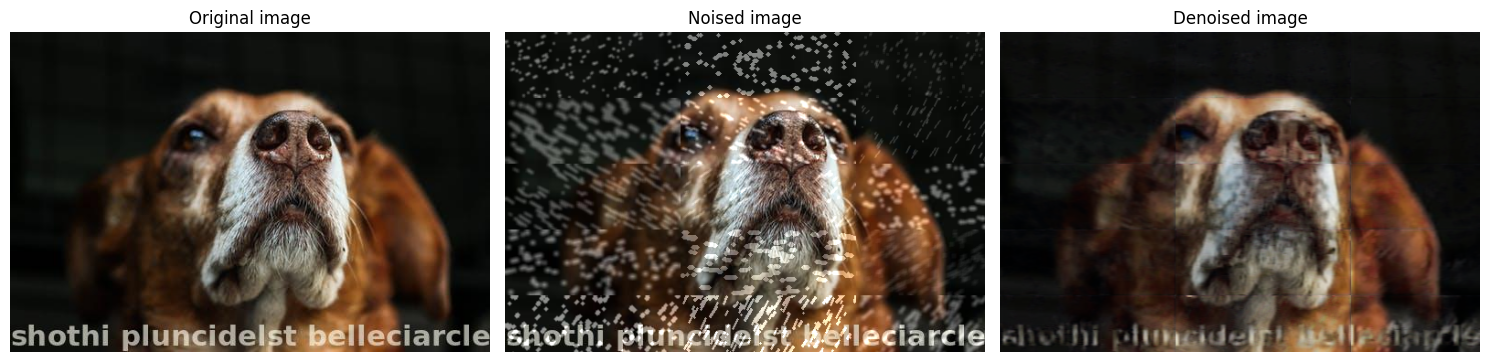

In [52]:
div_image = divide_image(original_image, add_rain)
# Convert list of patches into NumPy array
div_image = np.array(div_image, dtype=np.float32)
#print("Inputs shape:", div_image.shape)
original_noised_image = imgReconstruct(div_image, original_shape)

predictions = best_model.predict(div_image)
#print("Predictions shape:", predictions.shape)

result = imgReconstruct(predictions, original_shape)

plt.figure(figsize=(15, 6))

plt.subplot(131), plt.imshow(original_image)
plt.title("Original image")
plt.axis('off')

plt.subplot(132), plt.imshow(original_noised_image)
plt.title("Noised image")
plt.axis('off')

plt.subplot(133), plt.imshow(result)
plt.title("Denoised image")
plt.axis('off')

plt.tight_layout()
plt.show()